# 15 - Machine Learning Experiments

**Project:** AI Quantitative Trading & Strategy Optimisation System  
**Phase:** 8 — Machine Learning Experiments  
**Status:** Research implementation; run to generate development results.

## Scope and test-period policy

This notebook compares traditional ML forecasts with Phase 7 references. It does not implement trading signals, portfolio logic, backtesting, execution or live trading. It uses local acquisitions only and excludes macroeconomic/FRED/ALFRED inputs.

The Phase 7 holdout was already inspected. Existing observations are therefore used only for development walk-forward analysis; this notebook makes no claim of an untouched independent Phase 8 test. A future evaluation period must be collected after choices are frozen and evaluated once under a recorded protocol.

Approved Phase 6 target formulas, zero neutral band and 5/10/20 acquired-row horizons are reused unchanged. Price returns use Close and exclude dividends.


In [1]:
from pathlib import Path
import os, sys
import numpy as np
import pandas as pd
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/assets").is_dir())
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
from src.forecasting.ml_data import FEATURE_GROUPS, build_phase8_features_and_targets, load_local_market_data
from src.forecasting.ml_experiments import run_phase8_experiments
from src.forecasting.mlflow_tracking import configure_local_experiment
print("Project:", PROJECT_ROOT)
print("Tracking:", (PROJECT_ROOT / "data/mlflow/mlflow.db"))

Project: /home/anderjcruz/projects/Quantitative-Trading-Strategy
Tracking: /home/anderjcruz/projects/Quantitative-Trading-Strategy/data/mlflow/mlflow.db


## 1. Local data inventory

The loader requires exactly one local Parquet acquisition per configured asset, reads its manifest and leaves Raw data unchanged. Missing observations are preserved.


In [2]:
market_data, source_inventory = load_local_market_data(PROJECT_ROOT)
display(source_inventory)

,symbol,dataset_id,source_file,price_unit,unit_validation,rows,first_date,last_date,missing_close
0,NG.L,20261103T000455Z_8b505769,data/raw/market/yahoo_finance/NG.L/acquisition...,GBp,pending,7890,1995-12-11,2026-11-02,1
1,SSE.L,20261103T002507Z_de101edb,data/raw/market/yahoo_finance/SSE.L/acquisitio...,GBp,pending,9060,1991-06-17,2026-11-02,1
2,SVT.L,20261103T002515Z_fdac38df,data/raw/market/yahoo_finance/SVT.L/acquisitio...,GBp,pending,9455,1989-12-11,2026-11-02,1
3,^FTSE,20261103T002524Z_9c7eb120,data/raw/market/yahoo_finance/^FTSE/acquisitio...,index_points,not_applicable,11004,1984-01-03,2026-11-02,184


## 2. Approved feature groups and targets

B uses the five financial features from Phase 7. BC adds exact-date one-row peer returns. BCD adds the past-only Phase 6 regime indicators. All groups are compared on common complete dates while the full acquired-row timeline remains intact for purging.


In [3]:
feature_data, target_data = build_phase8_features_and_targets(market_data)
display(pd.DataFrame([{"asset": a, "group": g, "n_features": x.shape[1]} for a, groups in feature_data.items() for g, x in groups.items()]))

,asset,group,n_features
0,^FTSE,B_financial,5
1,^FTSE,BC_cross_asset,8
2,^FTSE,BCD_regime,14
3,NG.L,B_financial,5
4,NG.L,BC_cross_asset,8
5,NG.L,BCD_regime,14
6,SSE.L,B_financial,5
7,SSE.L,BC_cross_asset,8
8,SSE.L,BCD_regime,14
9,SVT.L,B_financial,5


## 3. Pre-specified candidates and validation

- Ridge regression: training-fold standardisation, alpha 1.0.
- Random Forest regression and three-class direction classification: 200 trees, max_features 0.5, min_samples_leaf 20; balanced class weights for classification; seed 42.
- Lasso/Elastic Net are deferred because redundant candidate features already create selection instability. XGBoost and LightGBM are excluded from this controlled first comparison due to added dependencies and complexity without established incremental value. Deep learning is out of scope.

Expanding walk-forward validation uses 70% initial training and 7.5% validation blocks, with horizon-based purging and no random split. Transformations fit only on training rows. Fixed configurations are declared before evaluation; no Phase 7 holdout tuning occurs.


## 4. Execute development comparisons

Return and volatility regression compare models with zero, expanding mean/median, trailing 252-label mean and an adjacent-acquired-row AR(1). Volatility also compares rolling historical volatility and GARCH(1,1). Direction retains labels -1/0/+1 and compares zero-direction and training-majority references.

Paired MAE differences use horizon-sized block bootstrap intervals sampled within folds. These are descriptive intervals and do not correct for multiple comparisons.


In [4]:
results = run_phase8_experiments(PROJECT_ROOT, market_data, source_inventory, feature_data, target_data)
print({name: frame.shape for name, frame in results.items()})
print("MLflow experiment ID:", configure_local_experiment(PROJECT_ROOT))

/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-T

/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-T

/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-T

/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


... (9 outputs left out)

/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/anderjcruz/projects/Quantitative-Trading-Strategy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


{'metrics': (180, 23), 'fold_metrics': (720, 22), 'comparisons': (792, 14), 'feature_importance': (3888, 8), 'predictions': (501060, 12)}
MLflow experiment ID: 4


## 5.1 Pilot parameter sensitivity (development only)

The following small, pre-specified sensitivity check uses the pilot NG.L, Group B, 10-row return case. It compares Ridge alpha 0.1 and 10 with the primary alpha 1.0 result, and Random Forest minimum leaf sizes 10 and 40 with the primary value 20. This is a stability diagnostic, not a tuning stage or final model selection.


In [5]:
from src.forecasting.ml_data import common_complete_mask, mask_features_to_common_dates
from src.forecasting.ml_metrics import block_bootstrap_mae_difference
from src.forecasting.ml_metrics import fold_regression_metrics
from src.forecasting.ml_metrics import regression_metrics
from src.forecasting.ml_models import build_regression_model, regression_walk_forward_predictions
from src.forecasting.ml_experiments import INITIAL_TRAIN_FRACTION, VALIDATION_FRACTION, SEED
import mlflow

pilot_asset, pilot_horizon = 'NG.L', 10
pilot_frame = market_data[pilot_asset]
pilot_target = target_data[pilot_asset][f'forward_return_{pilot_horizon}']
pilot_mask = common_complete_mask(feature_data[pilot_asset], pilot_target)
pilot_features = mask_features_to_common_dates(feature_data[pilot_asset], pilot_mask)['B_financial']
pilot_y = pilot_target.where(pilot_mask)
pilot_initial = int(len(pilot_frame) * INITIAL_TRAIN_FRACTION)
pilot_validation = int(np.ceil(len(pilot_frame) * VALIDATION_FRACTION))
sensitivity_specs = [
    ('ridge', {'alpha': 0.1}), ('ridge', {'alpha': 10.0}),
    ('random_forest', {'n_estimators': 200, 'max_features': 0.5, 'min_samples_leaf': 10}),
    ('random_forest', {'n_estimators': 200, 'max_features': 0.5, 'min_samples_leaf': 40}),
]
sensitivity_rows = []
for family, params in sensitivity_specs:
    pred = regression_walk_forward_predictions(
        pilot_features, pilot_y,
        model_factory=lambda f=family, p=params: build_regression_model(f, parameters=p, random_state=SEED),
        horizon=pilot_horizon, initial_train_size=pilot_initial, validation_size=pilot_validation,
    )
    metrics = regression_metrics(pred['actual'], pred['forecast'])
    with mlflow.start_run(experiment_id=configure_local_experiment(PROJECT_ROOT),
                          run_name=f'NG.L_h10_return_B_sensitivity_{family}_{params}'):
        mlflow.set_tags({'phase': '8', 'analysis_type': 'parameter_sensitivity',
                         'evaluation_role': 'development_only'})
        mlflow.log_params({'asset': pilot_asset, 'horizon': pilot_horizon,
                           'target': 'forward simple Close return', 'feature_group': 'B_financial',
                           'model_family': family, 'parameters': str(params), 'random_seed': SEED})
        mlflow.log_metrics({k: float(v) for k, v in metrics.items() if isinstance(v, (int, float))})
        mlflow.log_text(pred.to_csv(), 'walk_forward_predictions.csv')
    sensitivity_rows.append({'model': family, 'parameters': str(params), **metrics})

sensitivity_results = pd.DataFrame(sensitivity_rows)
display(sensitivity_results)

,model,parameters,mae,mse,rmse,forecast_bias,n_observations
0,ridge,{'alpha': 0.1},0.029739,0.001602,0.040026,0.001406,2354
1,ridge,{'alpha': 10.0},0.029738,0.001602,0.040026,0.001405,2354
2,random_forest,"{'n_estimators': 200, 'max_features': 0.5, 'mi...",0.030861,0.001679,0.040976,0.001447,2354
3,random_forest,"{'n_estimators': 200, 'max_features': 0.5, 'mi...",0.030269,0.001622,0.040272,0.001080,2354


## 5.2 Summary tables and visual checks

The tables below summarise asset-level results without pooling price-return errors across differently scaled assets. The plots keep targets and assets in separate panels. These displays aid comparison; they do not define a model-selection rule.


In [2]:
from IPython.display import display
import ast
import matplotlib.pyplot as plt

metric_table = results["metrics"].copy()
comparison_table = results["comparisons"].copy()
fold_table = results["fold_metrics"].copy()
importance_table = results["feature_importance"].copy()

# Mean over the three horizons; each asset remains on its own scale.
asset_scorecard = (
    metric_table.query("target in ['return', 'volatility']")
    .groupby(["target", "asset", "model", "feature_group"], as_index=False)
    .agg(n_configurations=("horizon", "nunique"),
         mean_mae=("mae", "mean"), mean_rmse=("rmse", "mean"),
         mean_forecast_bias=("forecast_bias", "mean"),
         mean_oos_r2_vs_expanding_mean=("oos_r2_vs_expanding_mean", "mean"))
    .sort_values(["target", "asset", "model", "feature_group"])
)
display(asset_scorecard.round(5))

benchmark_scorecard = (
    comparison_table.query("target in ['return', 'volatility']")
    .assign(interval_excludes_zero=lambda d:
            (d["block_bootstrap_ci_2_5"] > 0) | (d["block_bootstrap_ci_97_5"] < 0))
    .groupby(["target", "model", "benchmark"], as_index=False)
    .agg(n_configurations=("mae_difference_model_minus_benchmark", "count"),
         lower_mae_cases=("mae_difference_model_minus_benchmark", lambda x: int((x < 0).sum())),
         mean_mae_difference=("mae_difference_model_minus_benchmark", "mean"),
         unadjusted_intervals_excluding_zero=("interval_excludes_zero", "sum"))
    .sort_values(["target", "model", "benchmark"])
)
display(benchmark_scorecard.round(5))

classifier_scorecard = metric_table.query("target == 'direction'").groupby(
    "asset", as_index=False
).agg(mean_accuracy=("accuracy", "mean"),
     mean_balanced_accuracy=("balanced_accuracy", "mean"),
     mean_macro_f1=("f1_macro", "mean"),
     mean_roc_auc=("roc_auc_positive_vs_rest", "mean"),
     mean_pr_auc=("pr_auc_positive_vs_rest", "mean"))
majority_accuracy = (comparison_table.query(
    "target == 'direction' and benchmark == 'majority_class'"
).groupby("asset")["accuracy_vs_benchmark"].mean())
classifier_scorecard["majority_baseline_accuracy"] = classifier_scorecard["asset"].map(majority_accuracy)
display(classifier_scorecard.round(4))

if not importance_table.empty:
    top_features = (importance_table.groupby(
        ["target", "feature_group", "feature"], as_index=False)["importance"].mean()
        .sort_values(["target", "feature_group", "importance"],
                     ascending=[True, True, False])
        .groupby(["target", "feature_group"], group_keys=False).head(5))
    display(top_features.round(4))


,target,asset,model,feature_group,n_configurations,mean_mae,mean_rmse,mean_forecast_bias,mean_oos_r2_vs_expanding_mean
0,return,NG.L,random_forest,BCD_regime,3,0.03194,0.04208,0.00150,-0.02700
1,return,NG.L,random_forest,BC_cross_asset,3,0.03187,0.04201,0.00134,-0.02427
2,return,NG.L,random_forest,B_financial,3,0.03190,0.04201,0.00144,-0.02475
3,return,NG.L,ridge,BCD_regime,3,0.03140,0.04170,0.00172,-0.00884
4,return,NG.L,ridge,BC_cross_asset,3,0.03130,0.04159,0.00169,-0.00387
5,return,NG.L,ridge,B_financial,3,0.03132,0.04161,0.00167,-0.00502
6,return,SSE.L,random_forest,BCD_regime,3,0.03685,0.04898,-0.00063,-0.06225
7,return,SSE.L,random_forest,BC_cross_asset,3,0.03669,0.04880,0.00000,-0.05532
8,return,SSE.L,random_forest,B_financial,3,0.03672,0.04888,0.00007,-0.05883
9,return,SSE.L,ridge,BCD_regime,3,0.03636,0.04834,-0.00038,-0.03772


,target,model,benchmark,n_configurations,lower_mae_cases,mean_mae_difference,unadjusted_intervals_excluding_zero
0,return,random_forest,AR1_adjacent_pairs,36,0,0.00066,16
1,return,random_forest,expanding_mean,36,0,0.00067,17
2,return,random_forest,expanding_median,36,2,0.00065,16
3,return,random_forest,trailing_252_mean,36,18,-0.00012,7
4,return,random_forest,zero_return,36,2,0.00053,11
5,return,ridge,AR1_adjacent_pairs,36,8,0.00022,6
6,return,ridge,expanding_mean,36,7,0.00023,6
7,return,ridge,expanding_median,36,9,0.00020,4
8,return,ridge,trailing_252_mean,36,26,-0.00056,8
9,return,ridge,zero_return,36,14,0.00009,5


,asset,mean_accuracy,mean_balanced_accuracy,mean_macro_f1,mean_roc_auc,mean_pr_auc,majority_baseline_accuracy
0,NG.L,0.4690,0.3096,0.3159,0.4861,0.5303,0.5426
1,SSE.L,0.4647,0.3286,0.3217,0.4968,0.5495,0.5411
2,SVT.L,0.4852,0.3316,0.3308,0.5042,0.5364,0.5334
3,^FTSE,0.5304,0.5343,0.3539,0.5526,0.5931,0.5556


,target,feature_group,feature,importance
7,direction,BCD_regime,asset_realised_volatility_20,0.1429
5,direction,BCD_regime,asset_momentum_20,0.1246
4,direction,BCD_regime,asset_drawdown_20,0.1244
1,direction,BCD_regime,SSE.L__return_1,0.1222
8,direction,BCD_regime,asset_return_1,0.1163
22,direction,BC_cross_asset,asset_realised_volatility_20,0.1509
20,direction,BC_cross_asset,asset_momentum_20,0.1325
19,direction,BC_cross_asset,asset_drawdown_20,0.1308
16,direction,BC_cross_asset,SSE.L__return_1,0.1296
23,direction,BC_cross_asset,asset_return_1,0.1233


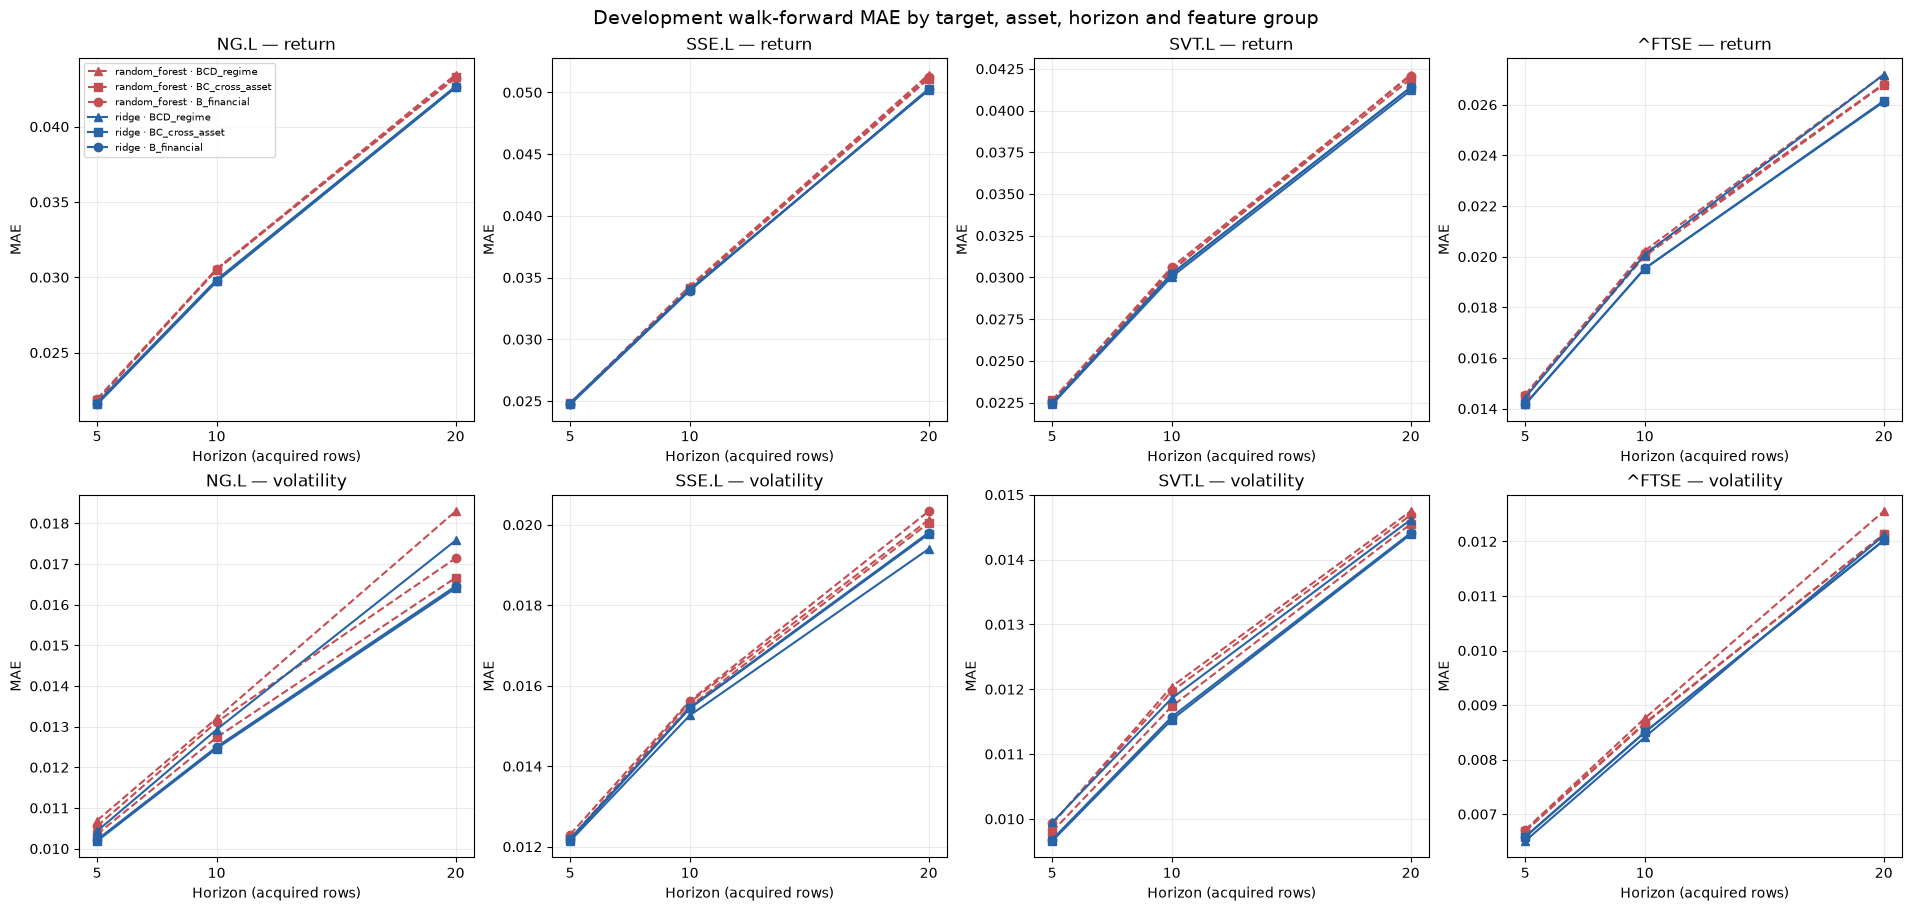

In [3]:
# Walk-forward MAE by horizon. Each panel has one asset and target; lines
# distinguish model family and feature group. Do not compare y-axis levels across assets.
asset_order = sorted(metric_table["asset"].unique())
model_styles = {"ridge": "-", "random_forest": "--"}
group_markers = {"B_financial": "o", "BC_cross_asset": "s", "BCD_regime": "^"}
fig, axes = plt.subplots(2, 4, figsize=(19, 9), constrained_layout=True)
for row, target_name in enumerate(("return", "volatility")):
    for col, asset_name in enumerate(asset_order):
        ax = axes[row, col]
        panel = metric_table.query("target == @target_name and asset == @asset_name")
        for (model_name, group_name), series in panel.groupby(["model", "feature_group"]):
            series = series.sort_values("horizon")
            ax.plot(series["horizon"], series["mae"],
                    color={"ridge": "#2864a5", "random_forest": "#c44e52"}[model_name],
                    linestyle=model_styles[model_name], marker=group_markers[group_name],
                    label=f"{model_name} · {group_name}")
        ax.set_title(f"{asset_name} — {target_name}")
        ax.set_xlabel("Horizon (acquired rows)")
        ax.set_ylabel("MAE")
        ax.set_xticks([5, 10, 20])
        ax.grid(alpha=0.25)
        if row == 0 and col == 0:
            ax.legend(fontsize=7, loc="best")
fig.suptitle("Development walk-forward MAE by target, asset, horizon and feature group", fontsize=14)
plt.show()


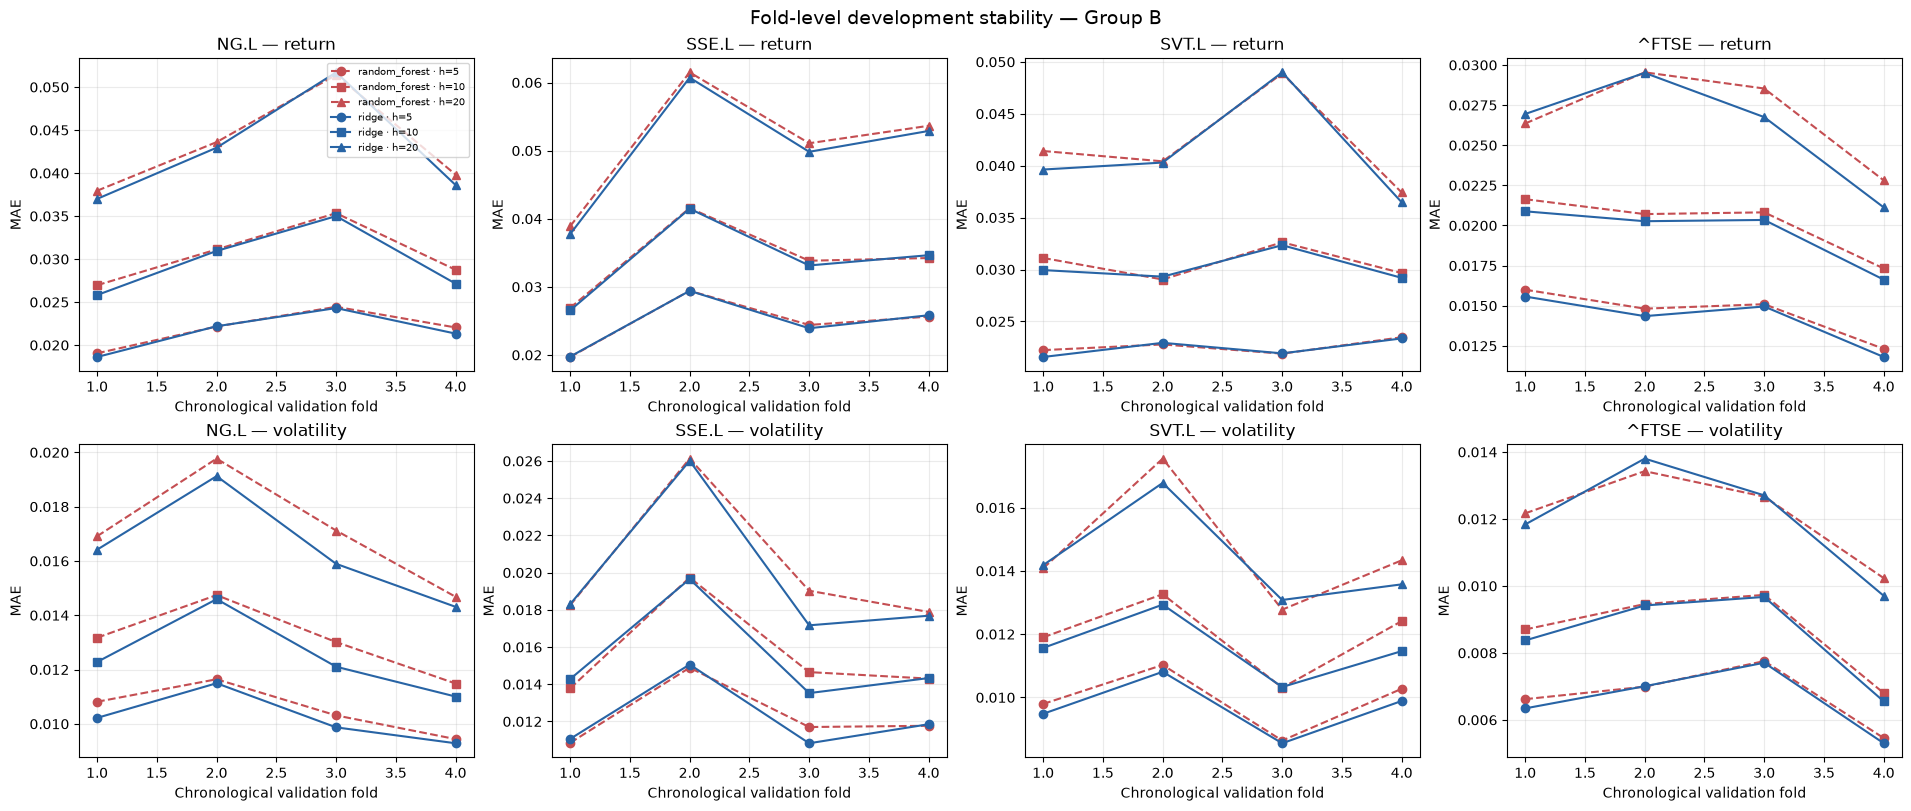

In [4]:
# Fold-level MAE for the financial-only group, to make period sensitivity visible.
# Fold numbers are chronological; they are not independent repeated trials.
fig, axes = plt.subplots(2, 4, figsize=(19, 8), constrained_layout=True)
for row, target_name in enumerate(("return", "volatility")):
    for col, asset_name in enumerate(asset_order):
        ax = axes[row, col]
        panel = fold_table.query(
            "target == @target_name and asset == @asset_name and feature_group == 'B_financial'"
        )
        for (model_name, horizon), series in panel.groupby(["model", "horizon"]):
            series = series.sort_values("fold")
            ax.plot(series["fold"], series["mae"],
                    color={"ridge": "#2864a5", "random_forest": "#c44e52"}[model_name],
                    linestyle=model_styles[model_name], marker={5: "o", 10: "s", 20: "^"}[int(horizon)],
                    label=f"{model_name} · h={horizon}")
        ax.set_title(f"{asset_name} — {target_name}")
        ax.set_xlabel("Chronological validation fold")
        ax.set_ylabel("MAE")
        ax.grid(alpha=0.25)
        if row == 0 and col == 0:
            ax.legend(fontsize=7, loc="best")
fig.suptitle("Fold-level development stability — Group B", fontsize=14)
plt.show()


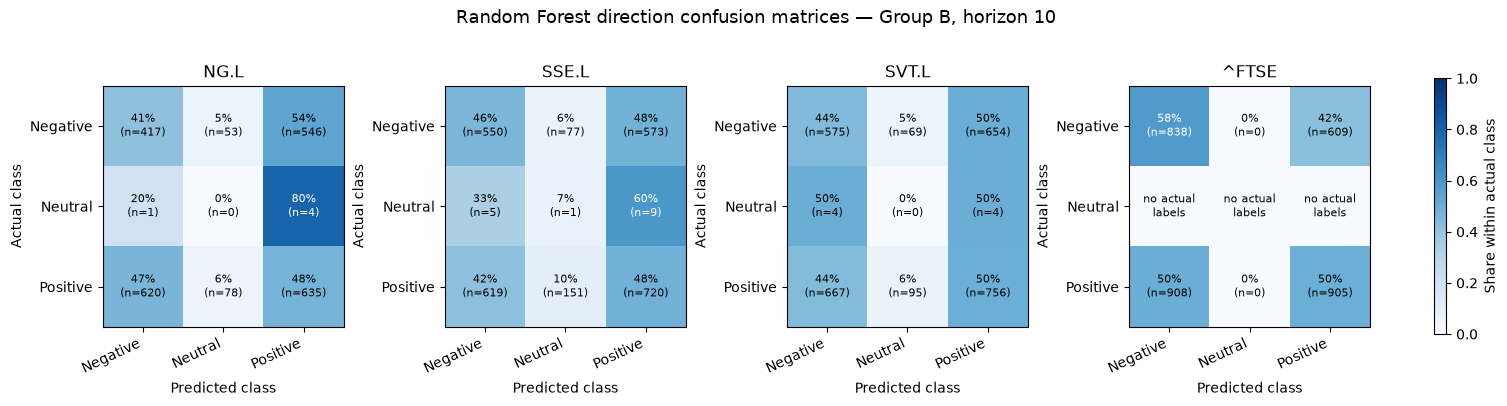

In [5]:
# Pilot-horizon (10 acquired rows) confusion matrices, with row normalisation.
# Counts are annotated so the rare neutral class is not hidden by percentages.
classes = [-1, 0, 1]
class_names = ["Negative", "Neutral", "Positive"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4), constrained_layout=True)
for ax, asset_name in zip(axes, asset_order):
    selected = metric_table.query(
        "target == 'direction' and asset == @asset_name and horizon == 10 and feature_group == 'B_financial'"
    )
    raw = selected.iloc[0]["confusion_matrix"]
    matrix = np.asarray(ast.literal_eval(raw) if isinstance(raw, str) else raw, dtype=int)
    totals = matrix.sum(axis=1)
    normalised = np.divide(matrix, totals[:, None], out=np.zeros_like(matrix, dtype=float), where=totals[:, None] > 0)
    image = ax.imshow(normalised, vmin=0, vmax=1, cmap="Blues")
    for i in range(3):
        for j in range(3):
            text = f"{normalised[i, j]:.0%}\n(n={matrix[i, j]})" if totals[i] else "no actual\nlabels"
            ax.text(j, i, text, ha="center", va="center", fontsize=8,
                    color="white" if normalised[i, j] > 0.55 else "black")
    ax.set_xticks(range(3), class_names, rotation=25, ha="right")
    ax.set_yticks(range(3), class_names)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_title(asset_name)
fig.colorbar(image, ax=axes, shrink=0.75, label="Share within actual class")
fig.suptitle("Random Forest direction confusion matrices — Group B, horizon 10", fontsize=13)
plt.show()


## 6. Detailed regression and fold stability

Reports MAE, MSE, RMSE, forecast bias and out-of-sample R² relative to expanding-mean forecasts. Review fold variation alongside pooled metrics.


In [6]:
display(results["metrics"].query("target != 'direction'").sort_values(["target","asset","horizon","feature_group","model"]))
display(results["fold_metrics"].sort_values(["target","asset","horizon","feature_group","model","fold"]))

,asset,horizon,target,feature_group,model,run_id,mae,mse,rmse,forecast_bias,...,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_positive,recall_positive,f1_positive,roc_auc_positive_vs_rest,pr_auc_positive_vs_rest,confusion_matrix
50,NG.L,5,return,BCD_regime,random_forest,4b86f94684804e5794bd59afd64b62e0,0.021823,0.000891,0.029853,0.000940,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49,NG.L,5,return,BCD_regime,ridge,324cad75e67b45c883bbebc4434896fa,0.021681,0.000880,0.029669,0.000859,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48,NG.L,5,return,BC_cross_asset,random_forest,410ec745d82249328e50a1c9482dd477,0.021825,0.000891,0.029850,0.000754,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
47,NG.L,5,return,BC_cross_asset,ridge,4d9bd12cf7b347d8870ba0287f869090,0.021564,0.000876,0.029589,0.000773,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46,NG.L,5,return,B_financial,random_forest,26f5b7c056de4cb482b3e6aff4ccb44d,0.021927,0.000893,0.029883,0.000730,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40,^FTSE,20,volatility,BCD_regime,ridge,c9d04c173d4449b88f02ad599ae64fbd,0.012110,0.000326,0.018051,0.003763,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
39,^FTSE,20,volatility,BC_cross_asset,random_forest,d8356f4b5f34417ab88feee40e27fcb9,0.012128,0.000321,0.017922,0.003553,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
38,^FTSE,20,volatility,BC_cross_asset,ridge,14a991b278234803b44d48a77a54b426,0.012018,0.000311,0.017649,0.003482,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
37,^FTSE,20,volatility,B_financial,random_forest,f1ebb164120f4ad7978a14b577ddd841,0.012131,0.000319,0.017860,0.003561,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,asset,horizon,target,feature_group,model,fold,mae,mse,rmse,forecast_bias,...,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_positive,recall_positive,f1_positive,roc_auc_positive_vs_rest,pr_auc_positive_vs_rest,confusion_matrix
236,NG.L,5,direction,BCD_regime,random_forest_classifier,1,NaN,NaN,NaN,NaN,...,0.298925,0.319269,0.298925,0.300310,0.462857,0.580645,0.515103,0.509407,0.470857,"[[98, 25, 187], [2, 0, 1], [98, 19, 162]]"
237,NG.L,5,direction,BCD_regime,random_forest_classifier,2,NaN,NaN,NaN,NaN,...,0.337653,0.351950,0.337653,0.344638,0.579288,0.549080,0.563780,0.544327,0.601150,"[[122, 12, 129], [0, 0, 1], [134, 13, 179]]"
238,NG.L,5,direction,BCD_regime,random_forest_classifier,3,NaN,NaN,NaN,NaN,...,0.327238,0.337274,0.327238,0.332023,0.544343,0.549383,0.546851,0.475170,0.525722,"[[115, 4, 147], [0, 0, 2], [131, 15, 178]]"
239,NG.L,5,direction,BCD_regime,random_forest_classifier,4,NaN,NaN,NaN,NaN,...,0.312055,0.332639,0.312055,0.322013,0.550336,0.512500,0.530744,0.512653,0.566816,"[[111, 18, 133], [2, 0, 1], [135, 21, 164]]"
232,NG.L,5,direction,BC_cross_asset,random_forest_classifier,1,NaN,NaN,NaN,NaN,...,0.284110,0.308751,0.284110,0.290620,0.445122,0.523297,0.481054,0.501735,0.465229,"[[102, 27, 181], [2, 0, 1], [108, 25, 146]]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,^FTSE,20,volatility,B_financial,random_forest,4,0.010234,0.000222,0.014902,0.005963,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
144,^FTSE,20,volatility,B_financial,ridge,1,0.011837,0.000239,0.015462,0.003591,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
145,^FTSE,20,volatility,B_financial,ridge,2,0.013802,0.000544,0.023327,0.003054,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
146,^FTSE,20,volatility,B_financial,ridge,3,0.012705,0.000261,0.016143,0.001926,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 7. Direction classification

Confusion matrix order is negative, neutral, positive. Accuracy, balanced accuracy, macro and positive-class precision/recall/F1, and positive-versus-rest ROC-AUC/PR-AUC are reported where defined.


In [7]:
display(results["metrics"].query("target == 'direction'").sort_values(["asset","horizon","feature_group"]))
display(results["comparisons"].query("target == 'direction'"))

,asset,horizon,target,feature_group,model,run_id,mae,mse,rmse,forecast_bias,...,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_positive,recall_positive,f1_positive,roc_auc_positive_vs_rest,pr_auc_positive_vs_rest,confusion_matrix
59,NG.L,5,direction,BCD_regime,random_forest_classifier,e3256bfb4ddb4e67a2b5d8eb5a82600c,NaN,NaN,NaN,NaN,...,0.317308,0.334132,0.317308,0.324872,0.531931,0.546837,0.539281,0.512586,0.537085,"[[446, 59, 596], [4, 0, 5], [498, 68, 683]]"
58,NG.L,5,direction,BC_cross_asset,random_forest_classifier,4b593502aaeb46cbacfcc8d16f9eea95,NaN,NaN,NaN,NaN,...,0.312612,0.330247,0.312612,0.320858,0.528332,0.530024,0.529177,0.506824,0.528102,"[[449, 64, 588], [6, 0, 3], [516, 71, 662]]"
57,NG.L,5,direction,B_financial,random_forest_classifier,20dd830f879c4643abf507eacb309b37,NaN,NaN,NaN,NaN,...,0.298602,0.328360,0.298602,0.312358,0.526793,0.511609,0.519090,0.509800,0.531203,"[[423, 107, 571], [6, 0, 3], [494, 116, 639]]"
74,NG.L,10,direction,BCD_regime,random_forest_classifier,f370c016530b4d3285c6f10d2aa426f3,NaN,NaN,NaN,NaN,...,0.317094,0.323996,0.317094,0.320261,0.555230,0.569392,0.562222,0.473586,0.542495,"[[388, 23, 605], [2, 0, 3], [541, 33, 759]]"
73,NG.L,10,direction,BC_cross_asset,random_forest_classifier,ff68e5952b6e47ff83dcc82aba1e4d80,NaN,NaN,NaN,NaN,...,0.307858,0.316191,0.307858,0.311908,0.546275,0.544636,0.545455,0.461235,0.533083,"[[385, 32, 599], [1, 0, 4], [571, 36, 726]]"
72,NG.L,10,direction,B_financial,random_forest_classifier,c84fde9059854165bba66b5e04352c0e,NaN,NaN,NaN,NaN,...,0.295601,0.312533,0.295601,0.303469,0.535865,0.476369,0.504369,0.465699,0.538851,"[[417, 53, 546], [1, 0, 4], [620, 78, 635]]"
89,NG.L,20,direction,BCD_regime,random_forest_classifier,bbb009ecd6b346aea57ef935b44e4c41,NaN,NaN,NaN,NaN,...,0.317324,0.323625,0.317324,0.320188,0.519037,0.535686,0.527230,0.481938,0.518749,"[[455, 22, 616], [1, 0, 3], [551, 28, 668]]"
88,NG.L,20,direction,BC_cross_asset,random_forest_classifier,ccba0aae153d45aba11388f41f811c20,NaN,NaN,NaN,NaN,...,0.310614,0.317213,0.310614,0.313415,0.510703,0.535686,0.522896,0.478831,0.519496,"[[433, 23, 637], [1, 0, 3], [548, 31, 668]]"
87,NG.L,20,direction,B_financial,random_forest_classifier,01081fd659f64681b18e4a3cc9f301dd,NaN,NaN,NaN,NaN,...,0.309798,0.321291,0.309798,0.315408,0.516735,0.507618,0.512136,0.484778,0.523286,"[[461, 42, 590], [2, 0, 2], [568, 46, 633]]"
104,SSE.L,5,direction,BCD_regime,random_forest_classifier,179053a59627499cb31bcab501d7b04f,NaN,NaN,NaN,NaN,...,0.331908,0.334070,0.331908,0.326173,0.529786,0.466108,0.495911,0.515072,0.535663,"[[601, 78, 581], [7, 1, 11], [681, 83, 667]]"


,asset,horizon,target,feature_group,model,benchmark,mae_difference_model_minus_benchmark,block_bootstrap_ci_2_5,block_bootstrap_ci_97_5,n_paired,block_length,replications,paired_dates,accuracy_vs_benchmark
60,^FTSE,5,direction,B_financial,random_forest_classifier,zero_direction,NaN,NaN,NaN,NaN,NaN,NaN,3270.0,0.000000
61,^FTSE,5,direction,B_financial,random_forest_classifier,majority_class,NaN,NaN,NaN,NaN,NaN,NaN,3270.0,0.553517
62,^FTSE,5,direction,BC_cross_asset,random_forest_classifier,zero_direction,NaN,NaN,NaN,NaN,NaN,NaN,3270.0,0.000000
63,^FTSE,5,direction,BC_cross_asset,random_forest_classifier,majority_class,NaN,NaN,NaN,NaN,NaN,NaN,3270.0,0.553517
64,^FTSE,5,direction,BCD_regime,random_forest_classifier,zero_direction,NaN,NaN,NaN,NaN,NaN,NaN,3270.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
787,SVT.L,20,direction,B_financial,random_forest_classifier,majority_class,NaN,NaN,NaN,NaN,NaN,NaN,2814.0,0.535892
788,SVT.L,20,direction,BC_cross_asset,random_forest_classifier,zero_direction,NaN,NaN,NaN,NaN,NaN,NaN,2814.0,0.003909
789,SVT.L,20,direction,BC_cross_asset,random_forest_classifier,majority_class,NaN,NaN,NaN,NaN,NaN,NaN,2814.0,0.535892
790,SVT.L,20,direction,BCD_regime,random_forest_classifier,zero_direction,NaN,NaN,NaN,NaN,NaN,NaN,2814.0,0.003909


## 8. Benchmark comparisons and feature behaviour

A positive model-minus-benchmark MAE difference means greater error for the ML model. Random Forest impurity importances are descriptive only; correlated inputs can divide or bias importance and no feature selection is based on this table.


In [8]:
display(results["comparisons"].query("target != 'direction'").sort_values(["target","asset","horizon","feature_group","model","benchmark"]))
importance = results["feature_importance"]
if not importance.empty:
    display(importance.groupby(["target","asset","horizon","feature_group","feature"], as_index=False)["importance"].agg(["mean","std","count"]).reset_index().sort_values("mean", ascending=False))

,asset,horizon,target,feature_group,model,benchmark,mae_difference_model_minus_benchmark,block_bootstrap_ci_2_5,block_bootstrap_ci_97_5,n_paired,block_length,replications,paired_dates,accuracy_vs_benchmark
223,NG.L,5,return,BCD_regime,random_forest,AR1_adjacent_pairs,0.000295,-0.000019,0.000607,2359.0,5.0,500.0,NaN,NaN
224,NG.L,5,return,BCD_regime,random_forest,expanding_mean,0.000347,-0.000008,0.000671,2359.0,5.0,500.0,NaN,NaN
225,NG.L,5,return,BCD_regime,random_forest,expanding_median,0.000344,-0.000022,0.000665,2359.0,5.0,500.0,NaN,NaN
226,NG.L,5,return,BCD_regime,random_forest,trailing_252_mean,0.000300,-0.000061,0.000671,2359.0,5.0,500.0,NaN,NaN
227,NG.L,5,return,BCD_regime,random_forest,zero_return,0.000298,-0.000054,0.000649,2359.0,5.0,500.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
162,^FTSE,20,volatility,B_financial,ridge,GARCH11,-0.000495,-0.000909,-0.000099,3240.0,20.0,500.0,NaN,NaN
163,^FTSE,20,volatility,B_financial,ridge,expanding_mean,-0.006568,-0.007757,-0.005204,3240.0,20.0,500.0,NaN,NaN
164,^FTSE,20,volatility,B_financial,ridge,expanding_median,-0.002668,-0.003793,-0.001508,3240.0,20.0,500.0,NaN,NaN
165,^FTSE,20,volatility,B_financial,ridge,rolling_historical_volatility,-0.000696,-0.001983,0.000546,3008.0,20.0,500.0,NaN,NaN


,index,target,asset,horizon,feature_group,feature,mean,std,count
808,808,volatility,SSE.L,20,B_financial,asset_realised_volatility_20,0.571944,0.040542,4
803,803,volatility,SSE.L,20,BC_cross_asset,asset_realised_volatility_20,0.561253,0.045371,4
965,965,volatility,^FTSE,20,BC_cross_asset,asset_realised_volatility_20,0.545773,0.018306,4
722,722,volatility,NG.L,20,BC_cross_asset,asset_realised_volatility_20,0.539341,0.003304,4
789,789,volatility,SSE.L,20,BCD_regime,asset_realised_volatility_20,0.537363,0.037791,4
...,...,...,...,...,...,...,...,...,...
254,254,direction,^FTSE,5,BCD_regime,volatility_regime_high_volatility,0.001499,0.000837,4
904,904,volatility,^FTSE,5,BCD_regime,volatility_regime_typical_volatility,0.001481,0.000291,4
251,251,direction,^FTSE,5,BCD_regime,trend_regime_downtrend,0.001286,0.000329,4
252,252,direction,^FTSE,5,BCD_regime,trend_regime_mixed_trend,0.001187,0.000527,4


## 9. Persist results and tracking references

Each MLflow run records experiment metadata, dataset identifier, target, feature group, model parameters, seed, software versions, metrics and fold predictions. Representative NG.L Group B 10-row models retain a last development-fold artifact; other runs avoid duplicating large model files. No artifact is a selected deployable model. Tracking is local SQLite with local artifacts; no remote service is configured.


In [9]:
RESULTS_DIR = PROJECT_ROOT / "reports/phase_8/development_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
for name, frame in results.items(): frame.to_csv(RESULTS_DIR / f"{name}.csv")
print("Saved:", RESULTS_DIR.relative_to(PROJECT_ROOT))
print("MLflow DB:", (PROJECT_ROOT / "data/mlflow/mlflow.db").relative_to(PROJECT_ROOT))

Saved: reports/phase_8/development_results
MLflow DB: data/mlflow/mlflow.db


## 10. Limitations and phase boundary

- These are development walk-forward results, not an independent final test.
- Acquired-row horizons are not verified exchange sessions; Close-based targets exclude dividends and historical denomination/corporate-action semantics remain open.
- Yahoo Finance licensing remains open. No new data or macro series were acquired or used.
- The corrected AR(1) comparison here uses adjacent acquired-row pairs. It does not modify the approved Phase 7 implementation or its findings.
- Overlapping outcomes and multiple comparisons limit inference. No arbitrary acceptance threshold, economic trading claim or profitability claim is made.
- Do not begin Phase 9 without separate explicit approval.
